### Setup & Import Preprocessor

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from transformers import AutoTokenizer
import sys
import os

# Menambahkan folder src ke path agar bisa import modul
sys.path.append('../src')
from preprocessing import MemePreprocessor

# Inisialisasi
pp = MemePreprocessor()
tokenizer = AutoTokenizer.from_pretrained("indolem/indobertweet-base-uncased")

# Load Sample Data
df_train = pd.read_csv('../data/train/metadata.csv').sample(5, random_state=42)

d:\PROYEK ML DAN AI\IndoMeme-XAI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\PROYEK ML DAN AI\IndoMeme-XAI\.venv\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


### Text Cleaning Audit (Slang & Icons)

In [2]:
results = []
for idx, row in df_train.iterrows():
    raw_ocr = row['ocr']
    clean_ocr = pp.clean_text(raw_ocr)
    results.append({'Raw OCR': raw_ocr, 'Cleaned OCR': clean_ocr})

pd.set_option('display.max_colwidth', None)
display(pd.DataFrame(results))

,Raw OCR,Cleaned OCR
0,NEWS\nSHIN TAE YONG TELAH UNFOLLOW AKUN ORANGHITAMBERBULU635 DI INSTAGRAM\nBagaimana menurut kalian?,news shin tae yong telah unfollow akun oranghitamberbulu635 di instagram bagaimana menurut kalian
1,bu anakmu yang dulu\nsering ibu carikan utang\nuntuk biaya sekolah skg\nudah bisa utang sendiri\nbu.,bu anakmu yang dulu sering ibu carikan utang untuk biaya sekolah sekarang sudah bisa utang sendiri bu
2,Right Ear:\ntanda-tanda kedatangan\nimam mahdi\n2024 terbaru full\n\nLeft Ear:\nfilm G30SP\nfull (audio),right ear tanda tanda kedatangan imam mahdi 2024 terbaru full left ear film g30sp full audio
3,Penghuni Facebook ketika COD,penghuni facebook ketika cod
4,Cari Pendamping hidup Pria Indonesia yg\njujur dan Setia Serta mau tinggal Di\nKAMBOJA,cari pendamping hidup pria indonesia yang jujur dan setia serta mau tinggal di kamboja


### Multimodal Integration Check ([SEP] Logic)

In [3]:
sample_row = df_train.iloc[0]
combined = f"{pp.clean_text(sample_row['ocr'])} [SEP] {pp.clean_text(sample_row['caption'])}"

print(f"--- Combined Text Example ---")
print(combined)

# Cek Tokenisasi
tokens = tokenizer.tokenize(combined)
print(f"\n--- Tokenization Sample ---")
print(tokens[:20], "... [TRUNCATED]")

--- Combined Text Example ---
news shin tae yong telah unfollow akun oranghitamberbulu635 di instagram bagaimana menurut kalian [SEP] visual ini menampilkan shin tae yong yang diberitakan telah berhenti mengikuti akun instagram oranghitamberbulu635 sebuah peristiwa yang menarik perhatian publik

--- Tokenization Sample ---
['news', 'shin', 'tae', 'yong', 'telah', 'unfoll', '##ow', 'akun', 'orang', '##hit', '##amber', '##bul', '##u', '##63', '##5', 'di', 'instagram', 'bagaimana', 'menurut', 'kalian'] ... [TRUNCATED]


### Visual Preprocessing Audit (Resizing)

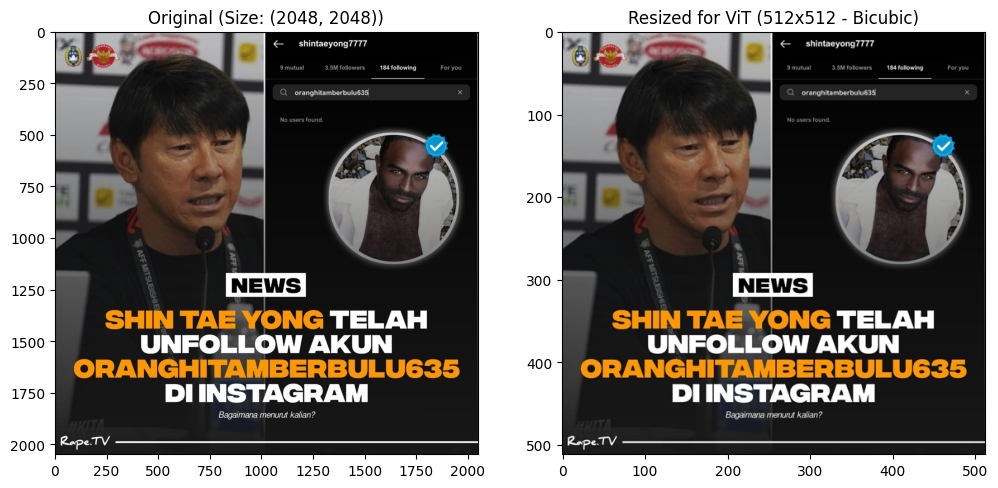

In [4]:
def plot_resize_comparison(img_path):
    img = Image.open(img_path).convert('RGB')
    
    # Simulasikan Bicubic Resize untuk ViT
    img_resized = img.resize((512, 512), resample=Image.BICUBIC)
    
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(img)
    ax[0].set_title(f"Original (Size: {img.size})")
    
    ax[1].imshow(img_resized)
    ax[1].set_title("Resized for ViT (512x512 - Bicubic)")
    plt.show()

# Test pada satu gambar dari folder data
sample_img_path = os.path.join('../data/train/', df_train.iloc[0]['local_path'])
plot_resize_comparison(sample_img_path)

### Token Length & Unknown Token Analysis

In [5]:
# Ambil 100 sampel untuk statistik cepat
df_audit = pd.read_csv('../data/train/metadata.csv').sample(100)
all_combined = df_audit.apply(lambda x: f"{pp.clean_text(x['ocr'])} [SEP] {pp.clean_text(x['caption'])}", axis=1)

# Hitung jumlah token per baris
token_counts = [len(tokenizer.encode(t)) for t in all_combined]

print(f"Rata-rata panjang token: {sum(token_counts)/100:.2f}")
print(f"Panjang token maksimal: {max(token_counts)}")

# Cek [UNK] tokens
encoded_samples = [tokenizer.encode(t) for t in all_combined]
unk_count = sum([1 for seq in encoded_samples if tokenizer.unk_token_id in seq])
print(f"Jumlah sampel dengan token [UNK]: {unk_count} / 100")

Rata-rata panjang token: 40.34
Panjang token maksimal: 83
Jumlah sampel dengan token [UNK]: 0 / 100
